# Notebook 3: Mixed Effects Models

## Why mixed effects models?
Each donor contributes samples from up to 4 brain regions. This means samples 
from the same donor are not independent — they share genetics, age, disease 
history, and post-mortem conditions. A standard t-test would ignore this and 
inflate false positives.

A mixed effects model handles this by treating donor as a "random effect" — 
it accounts for the fact that samples cluster within donors, and estimates the 
effect of TBI while controlling for this clustering, plus covariates like age, 
sex, and dementia status.

## Model structure
`expression ~ TBI + dementia + age + sex + (1 | donor)`

## Aims
1. Test whether TBI history is associated with expression of each channel gene
2. Test whether dementia status is associated with expression
3. Correct for multiple comparisons across 10 genes
4. Identify which genes and regions show the strongest associations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import warnings
warnings.filterwarnings('ignore')

PROJECT_ROOT = Path("..").resolve()
DATA_DIR     = PROJECT_ROOT / "data"
FIGURES_DIR  = PROJECT_ROOT / "figures"

merged = pd.read_csv(DATA_DIR / "master_analysis_table.csv")

# log-transform (same as notebook 2)
target_genes = [
    'PIEZO1', 'PIEZO2', 'TRPV4', 'TRPV1', 'TRPV2',
    'KCNK2', 'KCNK4', 'KCNK10', 'TMEM63A', 'TMEM63B'
]
for gene in target_genes:
    merged[f'{gene}_log2'] = np.log2(merged[gene] + 1)

# create region short labels
region_map = {
    'temporal neocortex': 'TCx',
    'hippocampus (hippocampal formation)': 'HIP',
    'white matter of forebrain': 'FWM',
    'parietal neocortex': 'PCx'
}
merged['region'] = merged['structure_name'].map(region_map)

print(f"Loaded {merged.shape[0]} samples")
print(f"Columns: {merged.columns.tolist()}")

Loaded 377 samples
Columns: ['rnaseq_profile_id', 'KCNK2', 'TMEM63A', 'TMEM63B', 'KCNK4', 'TRPV4', 'KCNK10', 'PIEZO1', 'TRPV1', 'TRPV2', 'PIEZO2', 'donor_id', 'structure_name', 'structure_acronym', 'hemisphere', 'ever_tbi_w_loc', 'act_demented', 'nincds_arda_diagnosis', 'age', 'sex', 'apo_e4_allele', 'braak', 'cerad', 'PIEZO1_log2', 'PIEZO2_log2', 'TRPV4_log2', 'TRPV1_log2', 'TRPV2_log2', 'KCNK2_log2', 'KCNK4_log2', 'KCNK10_log2', 'TMEM63A_log2', 'TMEM63B_log2', 'region']


In [2]:
# ── prepare variables for modelling ───────────────────────────────────────

# fix age: replace grouped entries with their midpoint
# e.g. "90-94" → 92, "95-99" → 97
def parse_age(age_val):
    age_str = str(age_val).strip()
    if '-' in age_str:
        parts = age_str.split('-')
        return (int(parts[0]) + int(parts[1])) / 2
    else:
        try:
            return float(age_str)
        except:
            return np.nan

merged['age_numeric'] = merged['age'].apply(parse_age)

# encode TBI and dementia as 0/1
merged['TBI'] = (merged['ever_tbi_w_loc'] == 'Y').astype(int)
merged['dementia'] = (merged['act_demented'] == 'Dementia').astype(int)

# encode sex as 0/1 (M=1, F=0)
merged['sex_numeric'] = (merged['sex'] == 'M').astype(int)

print("Variable preparation complete.")
print(f"\nTBI:      {merged['TBI'].value_counts().to_dict()}")
print(f"Dementia: {merged['dementia'].value_counts().to_dict()}")
print(f"Age range: {merged['age_numeric'].min():.0f} – {merged['age_numeric'].max():.0f}")
print(f"Sex:      {merged['sex_numeric'].value_counts().to_dict()}")

Variable preparation complete.

TBI:      {0: 198, 1: 179}
Dementia: {0: 197, 1: 180}
Age range: 77 – 97
Sex:      {1: 222, 0: 155}


In [5]:
# fix age parsing before running models
def parse_age(age_val):
    age_str = str(age_val).strip()
    if age_str == '100+':
        return 100.0
    elif '-' in age_str:
        parts = age_str.split('-')
        return (int(parts[0]) + int(parts[1])) / 2
    else:
        try:
            return float(age_str)
        except:
            return np.nan

merged['age_numeric'] = merged['age'].apply(parse_age)

# ── run mixed effects model for all 10 genes ──────────────────────────────
results = []

for gene in target_genes:
    formula = f"{gene}_log2 ~ TBI + dementia + age_numeric + sex_numeric"
    
    try:
        model  = smf.mixedlm(formula, data=merged, groups=merged["donor_id"])
        fitted = model.fit(reml=True, method='lbfgs')
        
        results.append({
            'gene':           gene,
            'TBI_coef':       fitted.params['TBI'],
            'TBI_pval':       fitted.pvalues['TBI'],
            'dementia_coef':  fitted.params['dementia'],
            'dementia_pval':  fitted.pvalues['dementia'],
            'n_samples':      int(fitted.nobs),
        })
        print(f"✓ {gene}")
        
    except Exception as e:
        print(f"✗ {gene} — error: {e}")

results_df = pd.DataFrame(results)
print("\nDone.")

✓ PIEZO1
✓ PIEZO2
✓ TRPV4
✓ TRPV1
✓ TRPV2
✓ KCNK2
✓ KCNK4
✓ KCNK10
✓ TMEM63A
✓ TMEM63B

Done.


In [6]:
# ── multiple comparisons correction ───────────────────────────────────────
# we tested 10 genes, so we correct p-values using FDR (Benjamini-Hochberg)
# this controls the false discovery rate — reduces chance of false positives
# a corrected p-value (q-value) < 0.05 is our significance threshold

# correct TBI p-values
_, results_df['TBI_qval'], _, _ = multipletests(
    results_df['TBI_pval'], method='fdr_bh'
)

# correct dementia p-values
_, results_df['dementia_qval'], _, _ = multipletests(
    results_df['dementia_pval'], method='fdr_bh'
)

# round for readability
results_df = results_df.round(4)

# flag significant results
results_df['TBI_sig']      = results_df['TBI_qval']      < 0.05
results_df['dementia_sig'] = results_df['dementia_qval'] < 0.05

print("=== MIXED EFFECTS MODEL RESULTS ===\n")
print("TBI effect (controlling for dementia, age, sex):")
print(results_df[['gene', 'TBI_coef', 'TBI_pval', 'TBI_qval', 'TBI_sig']]
      .sort_values('TBI_pval').to_string(index=False))

print("\nDementia effect (controlling for TBI, age, sex):")
print(results_df[['gene', 'dementia_coef', 'dementia_pval', 'dementia_qval', 'dementia_sig']]
      .sort_values('dementia_pval').to_string(index=False))

=== MIXED EFFECTS MODEL RESULTS ===

TBI effect (controlling for dementia, age, sex):
   gene  TBI_coef  TBI_pval  TBI_qval  TBI_sig
TMEM63A    0.1866    0.0896    0.8854    False
 PIEZO1    0.0545    0.1968    0.8854    False
 PIEZO2    0.0997    0.2906    0.8854    False
  TRPV2    0.0388    0.3546    0.8854    False
  TRPV1    0.0170    0.5578    0.8854    False
  KCNK2    0.0230    0.6046    0.8854    False
TMEM63B   -0.0110    0.7053    0.8854    False
  KCNK4    0.0149    0.7083    0.8854    False
 KCNK10   -0.0032    0.9127    0.9203    False
  TRPV4    0.0014    0.9203    0.9203    False

Dementia effect (controlling for TBI, age, sex):
   gene  dementia_coef  dementia_pval  dementia_qval  dementia_sig
  TRPV2         0.0451         0.2861         0.9350         False
  KCNK4         0.0313         0.4363         0.9350         False
  TRPV4         0.0099         0.4841         0.9350         False
  TRPV1        -0.0197         0.4982         0.9350         False
TMEM63A     

In [7]:
# ── region-specific models ─────────────────────────────────────────────────
# run the same model separately for each brain region
# this tests whether TBI effects are region-specific

regions = ['TCx', 'HIP', 'FWM', 'PCx']
region_results = []

for region in regions:
    region_data = merged[merged['region'] == region].copy()
    
    for gene in target_genes:
        formula = f"{gene}_log2 ~ TBI + dementia + age_numeric + sex_numeric"
        
        try:
            model  = smf.mixedlm(formula, data=region_data, 
                                  groups=region_data["donor_id"])
            fitted = model.fit(reml=True, method='lbfgs')
            
            region_results.append({
                'region':        region,
                'gene':          gene,
                'TBI_coef':      fitted.params['TBI'],
                'TBI_pval':      fitted.pvalues['TBI'],
                'n_samples':     int(fitted.nobs),
            })
        except Exception as e:
            region_results.append({
                'region':    region,
                'gene':      gene,
                'TBI_coef':  np.nan,
                'TBI_pval':  np.nan,
                'n_samples': np.nan,
            })

region_df = pd.DataFrame(region_results)

# apply FDR correction across all region-gene combinations
valid = region_df['TBI_pval'].notna()
_, region_df.loc[valid, 'TBI_qval'], _, _ = multipletests(
    region_df.loc[valid, 'TBI_pval'], method='fdr_bh'
)

region_df = region_df.round(4)
print("Region-specific TBI effects (sorted by p-value):")
print(region_df[['region', 'gene', 'TBI_coef', 'TBI_pval', 'TBI_qval']]
      .sort_values('TBI_pval').head(15).to_string(index=False))

Region-specific TBI effects (sorted by p-value):
region    gene  TBI_coef  TBI_pval  TBI_qval
   PCx   KCNK4    0.0886    0.0358    0.5060
   FWM TMEM63A    0.4440    0.0420    0.5060
   FWM  PIEZO2    0.3306    0.0464    0.5060
   TCx   KCNK4    0.0734    0.0519    0.5060
   PCx   KCNK2    0.0936    0.0632    0.5060
   HIP TMEM63A    0.1659    0.0948    0.5526
   FWM   TRPV1    0.0904    0.0967    0.5526
   FWM TMEM63B   -0.0951    0.1106    0.5528
   TCx  PIEZO1    0.0664    0.1741    0.6172
   HIP  PIEZO2    0.1068    0.1762    0.6172
   FWM   KCNK4   -0.1043    0.1938    0.6172
   PCx   TRPV2    0.0742    0.2013    0.6172
   HIP   TRPV2    0.0725    0.2088    0.6172
   PCx   TRPV1   -0.0426    0.2250    0.6172
   FWM  PIEZO1    0.0871    0.2314    0.6172


In [10]:
# ── run mixed effects model for all 10 genes ──────────────────────────────
# stores results in a list, one row per gene

results = []

for gene in target_genes:
    formula = f"{gene}_log2 ~ TBI + dementia + age_numeric + sex_numeric"
    
    try:
        model  = smf.mixedlm(formula, data=merged, groups=merged["donor_id"])
        fitted = model.fit(reml=True, method='lbfgs')
        
        # extract TBI and dementia coefficients and p-values
        results.append({
            'gene':           gene,
            'TBI_coef':       fitted.params['TBI'],
            'TBI_pval':       fitted.pvalues['TBI'],
            'dementia_coef':  fitted.params['dementia'],
            'dementia_pval':  fitted.pvalues['dementia'],
            'n_samples':      int(fitted.nobs),
        })
        print(f"✓ {gene}")
        
    except Exception as e:
        print(f"✗ {gene} — error: {e}")

results_df = pd.DataFrame(results)
print("\nDone.")

✓ PIEZO1
✓ PIEZO2
✓ TRPV4
✓ TRPV1
✓ TRPV2
✓ KCNK2
✓ KCNK4
✓ KCNK10
✓ TMEM63A
✓ TMEM63B

Done.


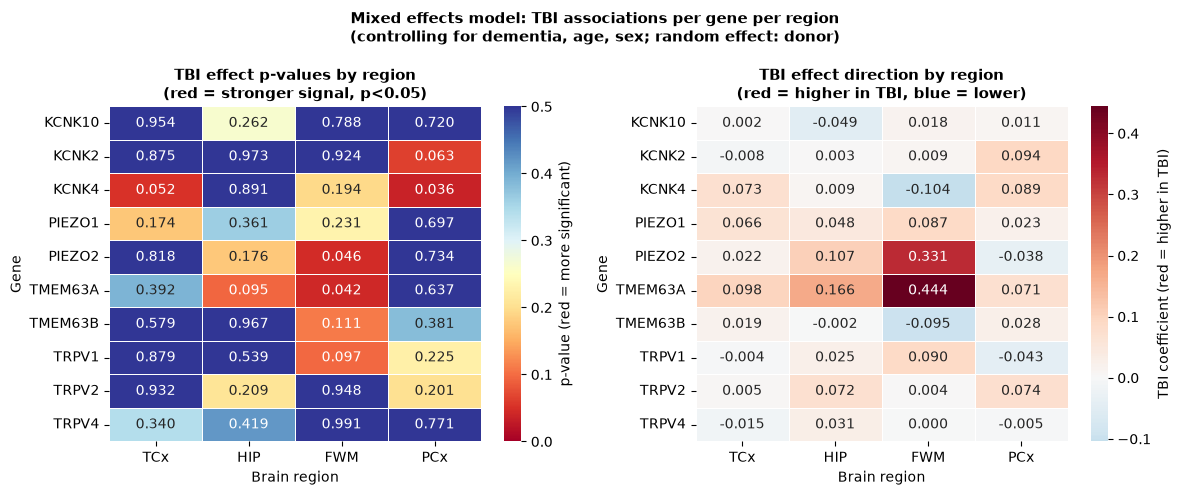

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# left: p-value heatmap — FLIPPED so red = significant (low p-value)
sns.heatmap(pivot_pval, ax=axes[0],
            cmap='RdYlBu',          # flipped — now red = low p-value
            vmin=0, vmax=0.5,
            annot=True, fmt='.3f',
            linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'p-value (red = more significant)'})
axes[0].set_title('TBI effect p-values by region\n(red = stronger signal, p<0.05)',
                   fontsize=11, fontweight='bold')
axes[0].set_xlabel('Brain region')
axes[0].set_ylabel('Gene')

# right: coefficient heatmap — keep red = higher in TBI
sns.heatmap(pivot_coef, ax=axes[1],
            cmap='RdBu_r', center=0,
            annot=True, fmt='.3f',
            linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'TBI coefficient (red = higher in TBI)'})
axes[1].set_title('TBI effect direction by region\n(red = higher in TBI, blue = lower)',
                   fontsize=11, fontweight='bold')
axes[1].set_xlabel('Brain region')
axes[1].set_ylabel('Gene')

plt.suptitle('Mixed effects model: TBI associations per gene per region\n'
             '(controlling for dementia, age, sex; random effect: donor)',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_mixed_model_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()